In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
# Works in Google Colab (reads from Google Drive) and locally (reads from this notebook's folder)
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    BASE = '/content/drive/MyDrive/SPIN_G3'      # upload the contents of this folder here
except ImportError:
    IN_COLAB = False
    BASE = os.getcwd()                            # run the notebook from its own folder
print('Data folder:', BASE)


In [3]:
df = pd.read_csv(os.path.join(BASE, 'Dataset_clean.csv'))

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 921438 entries, 0 to 921437
Data columns (total 26 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   userId                         921438 non-null  object 
 1   mes                            921438 non-null  object 
 2   account_age_days               921438 non-null  int64  
 3   ecommerce_tx_ratio_m           921438 non-null  float64
 4   cash_funding_ratio_m           583433 non-null  float64
 5   decline_ratio_m                921438 non-null  float64
 6   oxxo_tx_ratio_m                921438 non-null  float64
 7   merchant_entropy_m             921438 non-null  float64
 8   next_month_observed            921438 non-null  int64  
 9   has_next_month                 921438 non-null  int64  
 10  target_oxxo_migration          716001 non-null  float64
 11  oxxo_ratio_change_next_m       716001 non-null  float64
 12  target_ticket_growth          

In [5]:
df['mes'] = pd.to_datetime(df['mes'])

In [6]:
target_cols = [
    'target_oxxo_migration',
    'target_ticket_growth',
    'target_flip_out_30d',
    'target_flip_in_liquidity_30d',
    'target_flip_in_commercial_30d',
    'target_reactivation_30d',
]

for col in target_cols:
  df[col] = df[col].astype('Int64')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 921438 entries, 0 to 921437
Data columns (total 26 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   userId                         921438 non-null  object        
 1   mes                            921438 non-null  datetime64[ns]
 2   account_age_days               921438 non-null  int64         
 3   ecommerce_tx_ratio_m           921438 non-null  float64       
 4   cash_funding_ratio_m           583433 non-null  float64       
 5   decline_ratio_m                921438 non-null  float64       
 6   oxxo_tx_ratio_m                921438 non-null  float64       
 7   merchant_entropy_m             921438 non-null  float64       
 8   next_month_observed            921438 non-null  int64         
 9   has_next_month                 921438 non-null  int64         
 10  target_oxxo_migration          716001 non-null  Int64         
 11  

## Data Quality

In [8]:
nulls = df.isnull().sum()
print(nulls)

userId                                0
mes                                   0
account_age_days                      0
ecommerce_tx_ratio_m                  0
cash_funding_ratio_m             338005
decline_ratio_m                       0
oxxo_tx_ratio_m                       0
merchant_entropy_m                    0
next_month_observed                   0
has_next_month                        0
target_oxxo_migration            205437
oxxo_ratio_change_next_m         205437
target_ticket_growth             205482
ticket_change_next_m             205482
target_flip_out_30d              609119
target_flip_in_liquidity_30d     165590
target_flip_in_commercial_30d    165590
target_reactivation_30d          860840
account_level                         0
age_years                             0
Tx_count_m                            0
Tx_amount_sum_m                       0
Tx_amount_avg_m                       0
Intertx_cv_m                     325001
grupo                                 0


## Imputation

In [9]:
n_null_cf = df['cash_funding_ratio_m'].isnull().sum()
df['no_funding'] = df['cash_funding_ratio_m'].isnull().astype(int)
df['cash_funding_ratio_m'] = df['cash_funding_ratio_m'].fillna(-1)
print(f"cash_funding_ratio_m: {n_null_cf:,} nulls -> -1 (flagged in 'no_funding')")

cash_funding_ratio_m: 338,005 nulls -> -1 (flagged in 'no_funding')


In [10]:
n_null_cv = df['Intertx_cv_m'].isnull().sum()
df['low_tx_count'] = df['Intertx_cv_m'].isnull().astype(int)
df['Intertx_cv_m'] = df['Intertx_cv_m'].fillna(-1)
print(f"Intertx_cv_m: {n_null_cv:,} nulls -> -1 (flagged in 'low_tx_count')")

Intertx_cv_m: 325,001 nulls -> -1 (flagged in 'low_tx_count')


In [11]:
df.head()

,userId,mes,account_age_days,ecommerce_tx_ratio_m,cash_funding_ratio_m,decline_ratio_m,oxxo_tx_ratio_m,merchant_entropy_m,next_month_observed,has_next_month,...,account_level,age_years,Tx_count_m,Tx_amount_sum_m,Tx_amount_avg_m,Intertx_cv_m,grupo,creation_flow,no_funding,low_tx_count
0,SG3_00901f7cb0c3,2026-03-01,283,0.285714,-1.000000,0.363636,0.0,0.796312,1,1,...,2,61,7,1810.04,258.577143,0.550092,G3,POS,1,0
1,SG3_015488321254,2025-03-01,1053,0.000000,0.739156,0.000000,0.0,0.000000,1,1,...,2,59,0,0.00,0.000000,-1.000000,G3,MOBILE,0,1
2,SG3_0183ba93fc94,2026-04-01,1438,0.000000,1.000000,0.000000,0.0,1.980081,1,1,...,2,38,19,3074.18,161.798947,1.574470,G3,POS,0,0
3,SG3_01bc4427ad41,2025-11-01,450,1.000000,0.000000,0.000000,0.0,0.000000,1,1,...,2,21,6,859.60,143.266667,1.365012,G3,POS,0,0
4,SG3_02106149b463,2025-02-01,963,1.000000,1.000000,0.000000,0.0,1.596804,1,1,...,2,35,44,5253.53,119.398409,1.465184,G3,MOBILE,0,0


## Data Foundation

### Amount units

In [12]:
negative_amounts = (df['Tx_amount_sum_m'] < 0).sum()
print(f'Records with negative transaction amounts: {negative_amounts}')

if 'decline_ratio_m' in df.columns:
  min_decline = df['decline_ratio_m'].min()
  max_decline = df['decline_ratio_m'].max()
  out_of_bounds_decline = (
      (df['decline_ratio_m'] < 0) | (df['decline_ratio_m'] > 1)).sum()
  print(f'Decline ratio - Detected range: [{min_decline:.4f}, {max_decline:.4f}]')
  print(f'Values outside the [0, 1] interval: {out_of_bounds_decline}')

if 'Tx_amount_sum_m' in df.columns and 'Tx_amount_avg_m' in df.columns:
  valid_tx = df[(df['Tx_amount_sum_m'] > 0) & (df['Tx_amount_avg_m'] > 0)]
  inconsistent_units = (
      valid_tx['Tx_amount_avg_m'] > valid_tx['Tx_amount_sum_m']).sum()
  print(f'Records where average amount exceeds sum amount (unit inconsistency):'f' {inconsistent_units}')

print('\nStatistical summary of monetary amounts:')
print(df[['Tx_amount_sum_m', 'Tx_amount_avg_m']].describe())

Records with negative transaction amounts: 0
Decline ratio - Detected range: [0.0000, 1.0000]
Values outside the [0, 1] interval: 0
Records where average amount exceeds sum amount (unit inconsistency): 0

Statistical summary of monetary amounts:
       Tx_amount_sum_m  Tx_amount_avg_m
count    921438.000000    921438.000000
mean       2357.504926       255.289459
std        5116.790605       508.464666
min           0.000000         0.000000
25%         165.070000        58.104071
50%         824.230000       138.990000
75%        2562.962500       291.615937
max      210705.400000    121090.500000


### Approved vs declined

In [13]:
if "Tx_count_m" in df.columns and "Tx_amount_sum_m" in df.columns:
  approved_active_records = (
      (df["Tx_count_m"] > 0) & (df["Tx_amount_sum_m"] > 0)).sum()
  print("Records with active approved purchase transactions:"f" {approved_active_records}")
else:
  print("No Approved transaction columns.")

if "decline_ratio_m" in df.columns:
  mean_friction = df["decline_ratio_m"].mean()
  max_friction = df["decline_ratio_m"].max()
  print(f"Mean decline ratio (friction metric) across dataset: {mean_friction:.4f}")
  print(f"Max decline ratio detected: {max_friction:.4f}")
else:
  print("No 'decline_ratio_m'")

Records with active approved purchase transactions: 800427
Mean decline ratio (friction metric) across dataset: 0.2708
Max decline ratio detected: 1.0000


### Degenerate Features

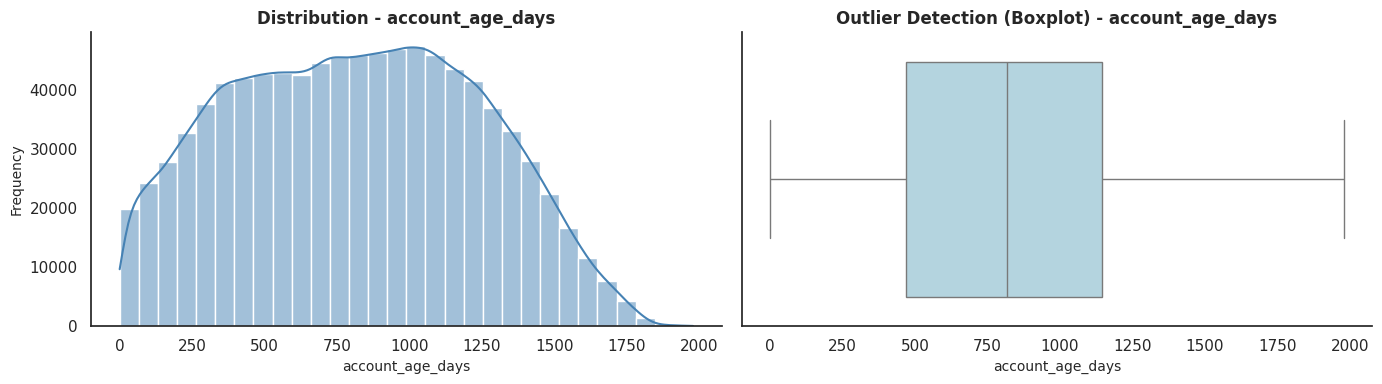

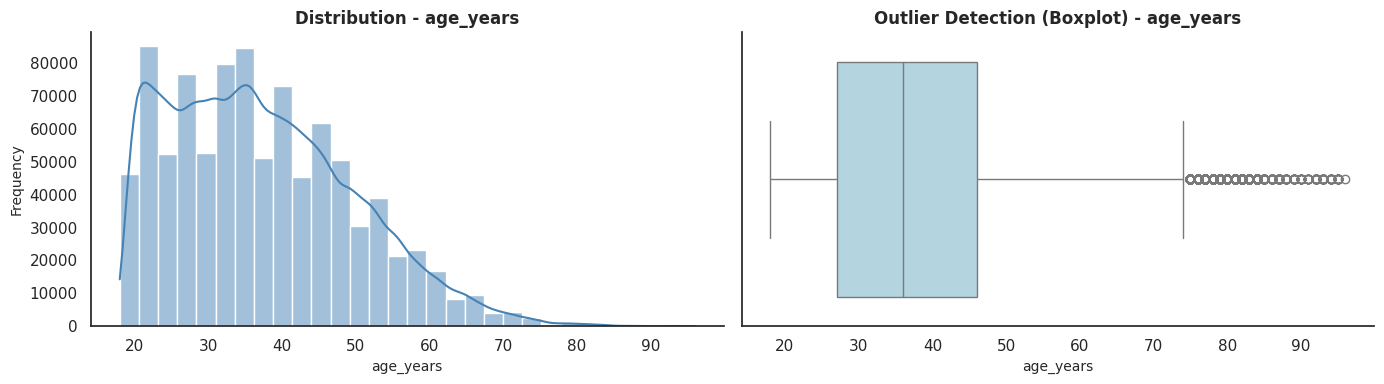

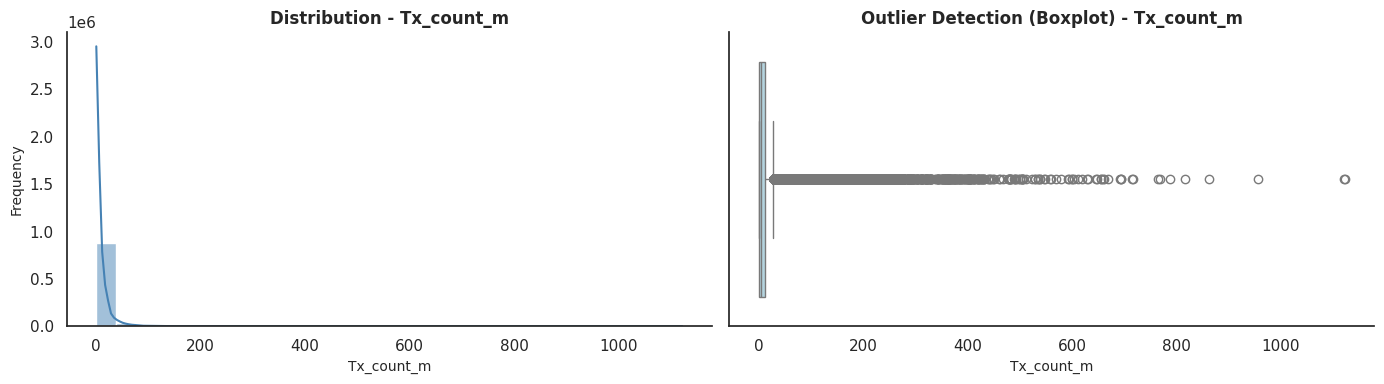

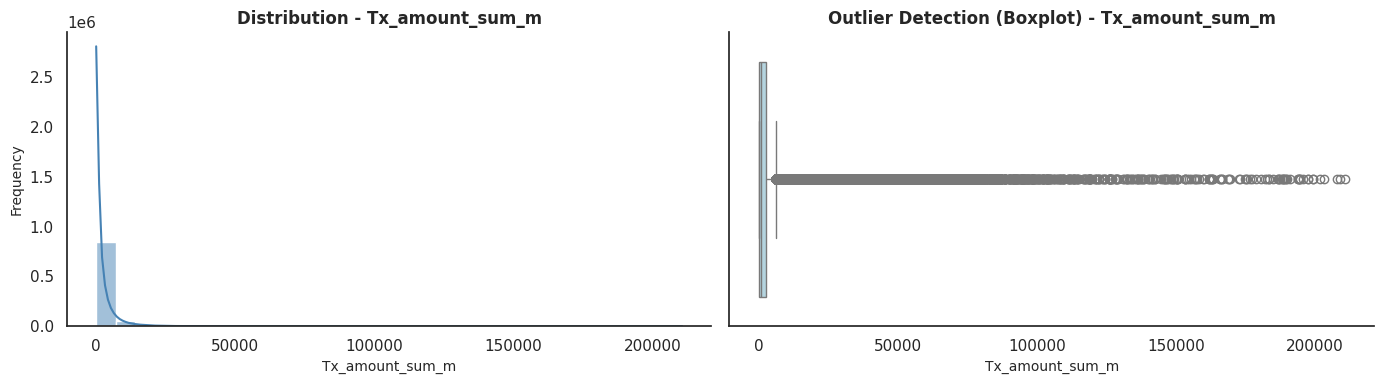

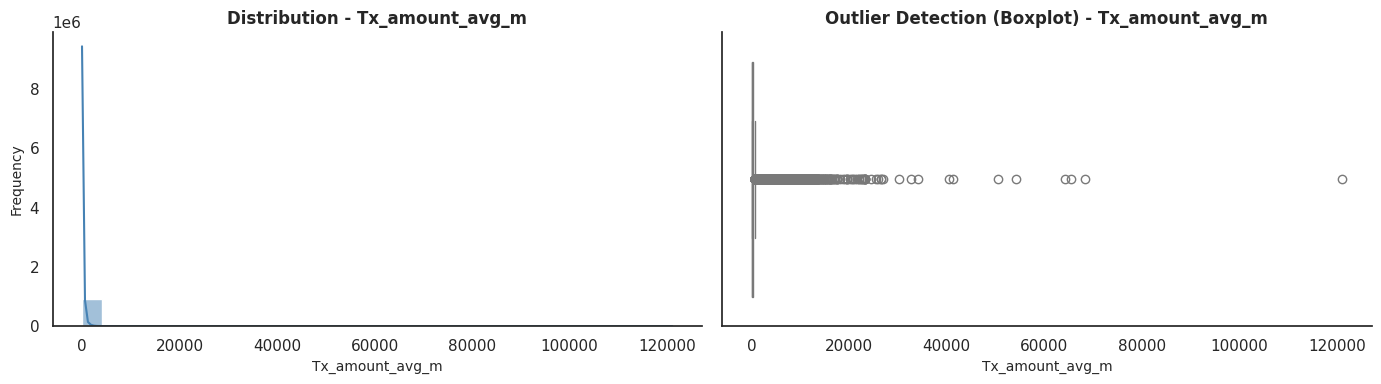

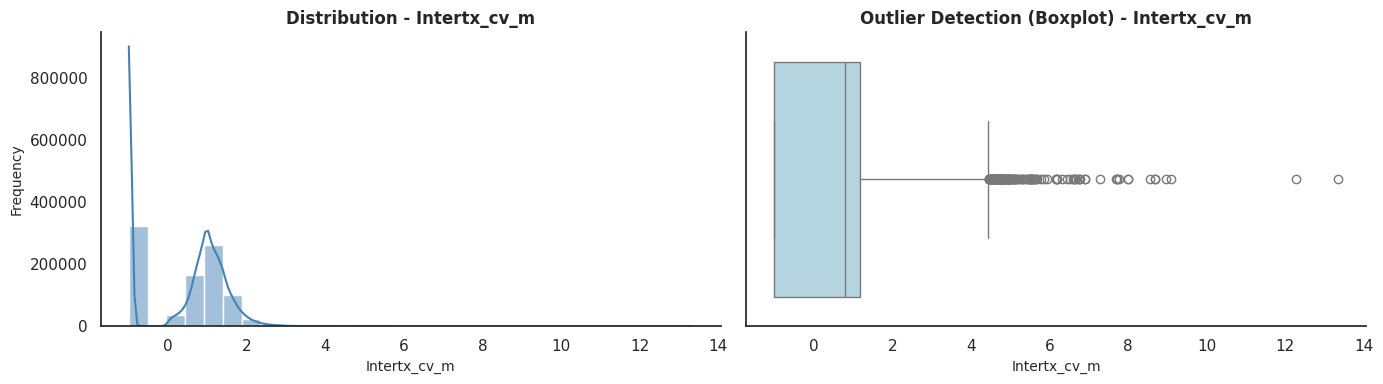

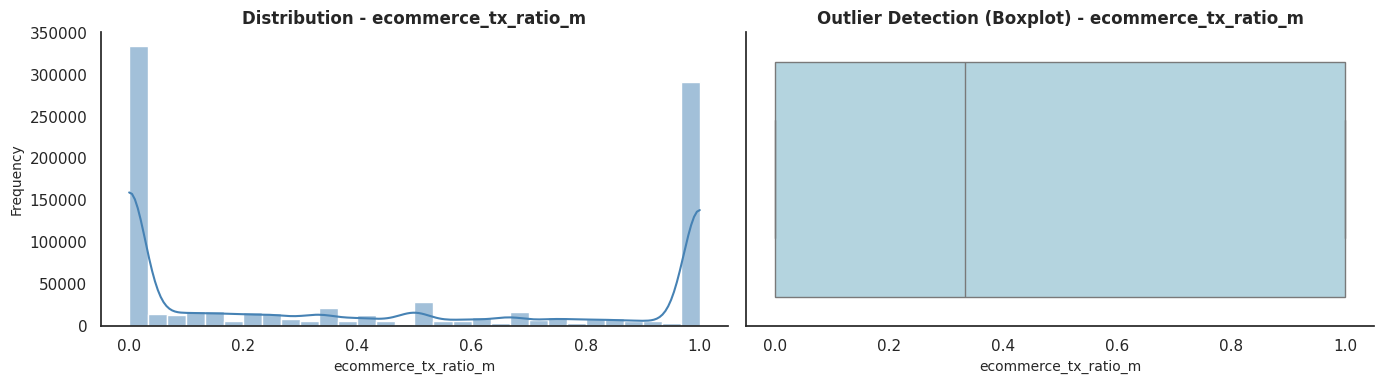

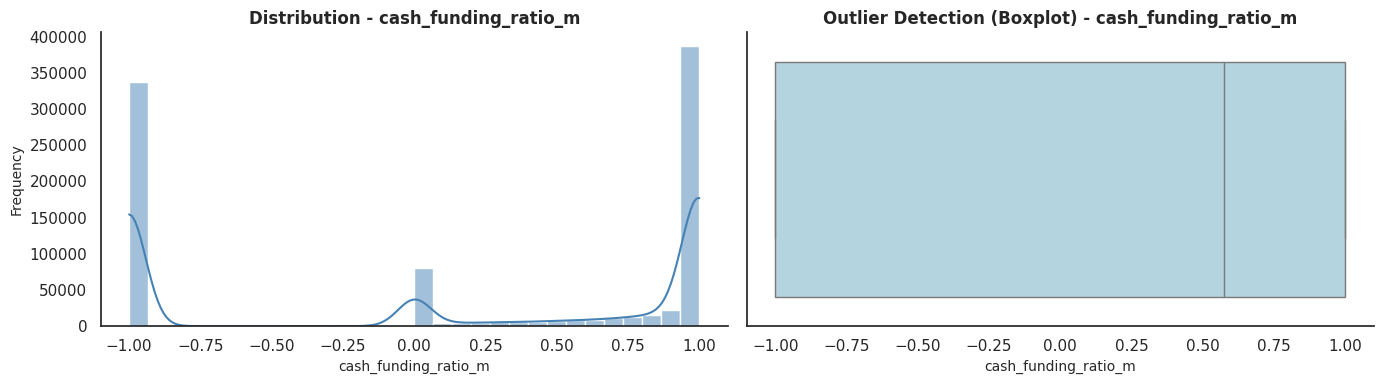

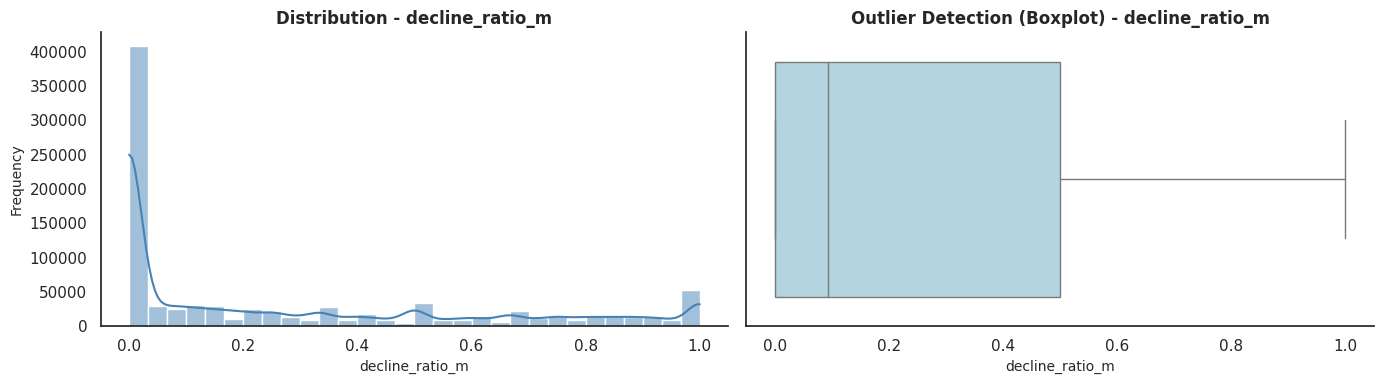

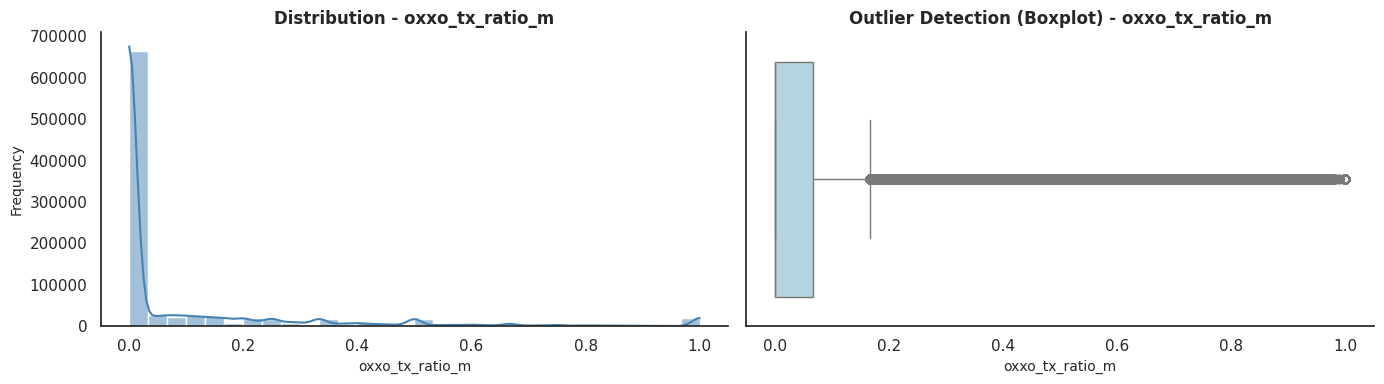

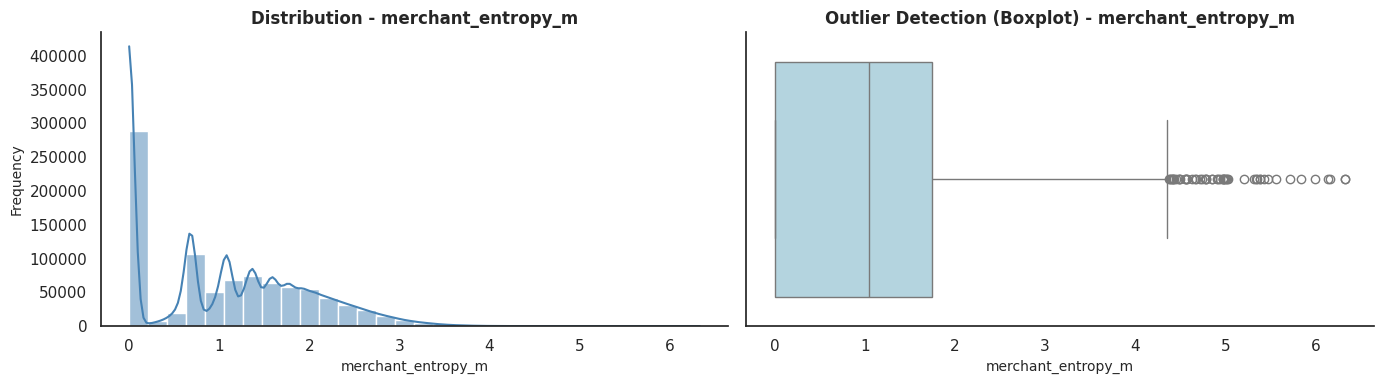

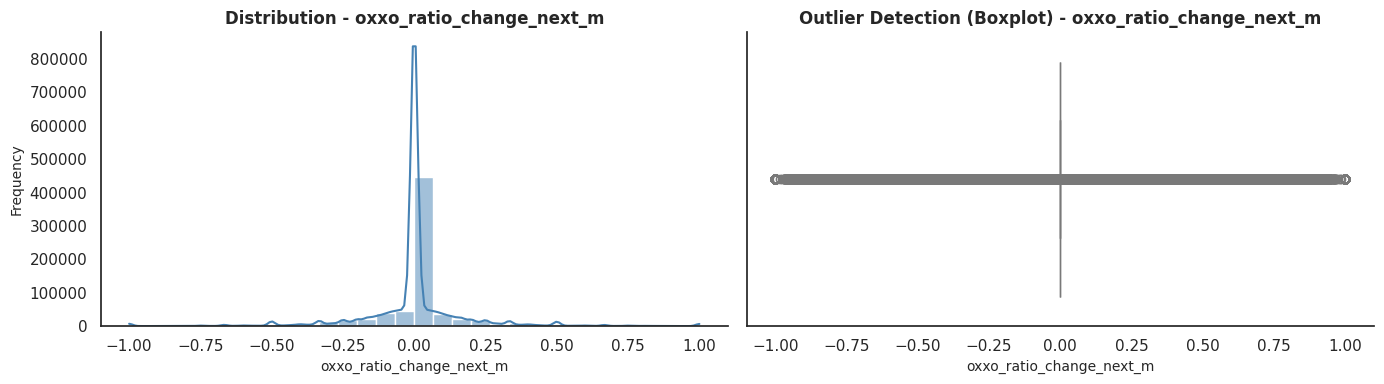

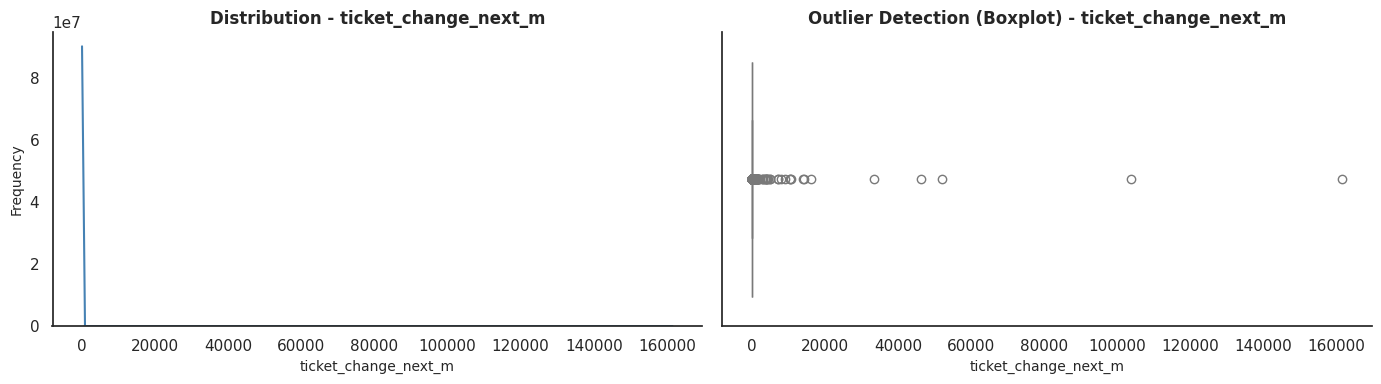

In [14]:
vars_to_plot = [
    "account_age_days",
    "age_years",
    "Tx_count_m",
    "Tx_amount_sum_m",
    "Tx_amount_avg_m",
    "Intertx_cv_m",
    "ecommerce_tx_ratio_m",
    "cash_funding_ratio_m",
    "decline_ratio_m",
    "oxxo_tx_ratio_m",
    "merchant_entropy_m",
    "oxxo_ratio_change_next_m",
    "ticket_change_next_m",
]
sns.set_theme(style="white")
for col in vars_to_plot:
  fig, axes = plt.subplots(1, 2, figsize=(14, 4))

  # 1. Histograma con curva KDE
  sns.histplot(
      data=df, x=col, kde=True, ax=axes[0], color="steelblue", bins=30
  )
  axes[0].set_title(f"Distribution - {col}", fontsize=12, fontweight="bold")
  axes[0].set_xlabel(col, fontsize=10)
  axes[0].set_ylabel("Frequency", fontsize=10)
  sns.despine(ax=axes[0])

  # 2. Boxplot (detección de outliers)
  sns.boxplot(data=df, x=col, ax=axes[1], color="lightblue")
  axes[1].set_title(
      f"Outlier Detection (Boxplot) - {col}", fontsize=12, fontweight="bold"
  )
  axes[1].set_xlabel(col, fontsize=10)
  sns.despine(ax=axes[1])

  plt.tight_layout()
  plt.show()

## Purchase Persona



In [15]:
df_cluster = pd.read_csv(os.path.join(BASE, 'Evidence 3', 'g3_clustering_features.csv'))


## Propensity Model

In [16]:
df_propensity = pd.read_csv(os.path.join(BASE, 'Evidence 3', 'g3_propensity_model_dataset.csv'))

## Executive Dashboard (Streamlit)

This section turns the results of the project into an interactive **Streamlit dashboard for Spin executives**, focused on **CLTV, OXXO spend share, average monthly spend and account age**.

| Tab | What it shows |
|---|---|
| **Overview** | A short guide to the 4 tabs, commission sliders (OXXO and outside OXXO, 0.25%-2.0%) that recompute CLTV, 5 KPIs (users, OXXO spend share, Flip-Out rate, avg monthly spend, avg CLTV) and users / revenue / CLTV by persona |
| **Personas** | One card per persona (name, size, value, profile, Flip-Out rate) + radar / heatmap / side-by-side comparison |
| **Target list** | Users ranked by Flip-Out score, filterable by persona and score decile, with a capacity slider (5%–30%) that compares flip-outs captured by the model vs. random selection |
| **Model** | Current model version, PR-AUC, capture at 10%, top drivers, performance by persona and a comparison with the previous model |

**Before running:** upload the folder `dashboard_inputs` to `MyDrive/SPIN/Evidence 3/` in Google Drive. It holds the outputs of the persona (K-Means) and Flip-Out (gradient boosting) stages:
`persona_labels.csv`, `scores_T2.csv`, `F10_shap_mean_abs.csv`, `LR_coefficients.csv`, `T7_best_configs.csv`.

The cells below (1) install Streamlit, (2) build the dashboard tables from `df` (the monthly dataset loaded above) and those files, (3) write `app.py`, and (4) launch the dashboard and show it **inside this notebook** plus a link to open it in a new tab.

**CLTV method (same as the CLTV-by-persona deck):** CLTV per user = avg monthly spend × blended commission × lifespan (months), where blended commission = OXXO spend share × 0.5% + non-OXXO share × 1.0% (team assumptions; Spin does not publish its rates) and lifespan = account age in months. The two commissions can be changed with the sliders in the Overview tab; CLTV and revenue update in every tab.

**Colors:** the dashboard uses the Spin by OXXO palette (purple, orange, white and light blue), set in the configuration cell and in `app.py`. It has a light and a dark theme: switch with the menu (top right): System / Light / Dark.

In [17]:
%pip install -q streamlit plotly

In [18]:
# ---------- Dashboard configuration ----------
import os, json
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

INPUT_DIR = os.path.join(BASE, 'Evidence 3', 'dashboard_inputs')   # folder uploaded to Google Drive
APP_DIR = os.path.join(os.getcwd(), 'spin_dashboard')                # where app.py and its data are written
DATA_DIR = os.path.join(APP_DIR, 'data')
os.makedirs(DATA_DIR, exist_ok=True)

REQUIRED = ['persona_labels.csv', 'scores_T2.csv', 'F10_shap_mean_abs.csv',
            'LR_coefficients.csv', 'T7_best_configs.csv']
missing = [f for f in REQUIRED if not os.path.exists(os.path.join(INPUT_DIR, f))]
assert not missing, f'Upload these files to {INPUT_DIR}: {missing}'

# CLTV assumptions (team assumptions, same as the CLTV-by-persona deck)
C_OXXO, C_OUT = 0.005, 0.010        # commission on OXXO spend / on spend outside OXXO
DAYS_PER_MONTH = 30.4375
T2_START, T2_END = '2025-12-01', '2026-05-01'   # observation window of the scoring snapshot T2 (31-May-2026)

# Spin by OXXO palette (purple, orange, white, light blue)
PURPLE, ORANGE, LIGHT_BLUE, LAVENDER = '#6A2BC4', '#FF7A00', '#5EC4F0', '#B79CF2'

# Streamlit theme read at launch: a light and a dark version (neutral text, purple only as accent).
# Viewers switch with the menu (top right): System / Light / Dark.
THEME = """[theme]
font = "sans-serif"

[theme.light]
primaryColor = "#6A2BC4"
backgroundColor = "#FFFFFF"
secondaryBackgroundColor = "#F4F3F7"
textColor = "#1F1E24"

[theme.dark]
primaryColor = "#9B6BF2"
backgroundColor = "#14121A"
secondaryBackgroundColor = "#221F2B"
textColor = "#ECEAF1"
"""
# Logos shown in the dashboard (Spin header; OXXO vs. Walmart / H-E-B / Soriana next to the commission sliders)
import shutil
LOGO_DIR = os.path.join(INPUT_DIR, 'logos')
ASSET_DIR = os.path.join(APP_DIR, 'assets')
os.makedirs(ASSET_DIR, exist_ok=True)
for f in ['spin_logo.svg', 'oxxo.svg', 'walmart.svg', 'heb.png', 'soriana.svg']:
    if os.path.exists(os.path.join(LOGO_DIR, f)):
        shutil.copy(os.path.join(LOGO_DIR, f), os.path.join(ASSET_DIR, f))
    else:
        print('Logo not found (the dashboard shows the name instead):', os.path.join(LOGO_DIR, f))

os.makedirs(os.path.join(APP_DIR, '.streamlit'), exist_ok=True)
with open(os.path.join(APP_DIR, '.streamlit', 'config.toml'), 'w') as f:
    f.write(THEME)

# Persona names, colors and profile (K-Means, k = 4, fitted on 2025)
PERSONAS = {
    1: dict(name='Light Mobile Occasional', color=LIGHT_BLUE,
            profile='Half of the base. Opened the account in the app but buys rarely (about 2 purchases a month) '
                    'and spends little; almost never at OXXO.'),
    2: dict(name='Engaged Mobile Power User', color=PURPLE,
            profile='One third of the users and three quarters of the revenue. Frequent, diverse, high spend; '
                    'already buys mostly outside OXXO.'),
    3: dict(name='Counter-onboarded Steady Spender', color=LAVENDER,
            profile='Small group onboarded at the OXXO counter (not in the app). Active every month with steady, '
                    'mid-to-high spend and the highest retention.'),
    4: dict(name='OXXO-Dependent Loyalist', color=ORANGE,
            profile='Half of their spend happens at OXXO. Low ticket, low diversity and low CLTV; '
                    'the card works as an OXXO wallet.'),
}

# Model card - EDIT the "previous version" and "changes" text if your last delivered version was different
MODEL_VERSION = 'v2.0'
PREVIOUS_VERSION = 'v1.0'
print('Inputs found in', INPUT_DIR)

Inputs found in /content/drive/MyDrive/SPIN_G3/Evidence 3/dashboard_inputs


### 1. Build the dashboard data

In [19]:
# ---------- 1. Persona table (2025 behaviour + CLTV) ----------
m = df.copy()
m['mes'] = pd.to_datetime(m['mes'])
m['oxxo_amt'] = m['oxxo_tx_ratio_m'] * m['Tx_amount_sum_m']        # OXXO spend = OXXO share of tx x spend

labels = pd.read_csv(os.path.join(INPUT_DIR, 'persona_labels.csv'))
persona_2025 = labels.query("split == 'train_2025'").set_index('userId')['cluster']

first_flow = (m.sort_values('mes').groupby('userId')['creation_flow'].first() == 'MOBILE').astype(int)
age_days = m.groupby('userId')['account_age_days'].max()             # account age at the last observed month

m25 = m[m['mes'] < '2026-01-01']
act25 = m25[m25['Tx_count_m'] > 0]
g, ga = m25.groupby('userId'), act25.groupby('userId')
u = pd.DataFrame({
    'avg_monthly_spend': g['Tx_amount_sum_m'].mean(),
    'spend_2025': g['Tx_amount_sum_m'].sum(),
    'oxxo_spend_2025': g['oxxo_amt'].sum(),
    'tx_per_month': g['Tx_count_m'].mean(),
    'active_months_pct': (m25['Tx_amount_sum_m'] > 0).groupby(m25['userId']).mean(),
    'merchant_entropy': ga['merchant_entropy_m'].mean(),
    'ecommerce_ratio': ga['ecommerce_tx_ratio_m'].mean(),
    'decline_rate': ga['decline_ratio_m'].mean(),
    'avg_ticket': ga['Tx_amount_avg_m'].mean(),
    'age_years': g['age_years'].last(),
}).fillna(0)
u['account_age_days'] = age_days
u['app_onboarded'] = first_flow
u['persona_id'] = persona_2025
u = u.dropna(subset=['persona_id'])
u['persona_id'] = u['persona_id'].astype(int)

def blended(oxxo_share):
    return oxxo_share * C_OXXO + (1 - oxxo_share) * C_OUT

def persona_row(x):
    oxxo = x['oxxo_spend_2025'].sum() / x['spend_2025'].sum()
    life = x['account_age_days'].mean() / DAYS_PER_MONTH
    spend = x['avg_monthly_spend'].mean()
    return pd.Series({
        'users': len(x), 'avg_monthly_spend': spend, 'oxxo_spend_share': oxxo,
        'spend_2025': x['spend_2025'].sum(), 'oxxo_spend_2025': x['oxxo_spend_2025'].sum(),
        'account_age_days': x['account_age_days'].mean(), 'lifespan_months': life,
        'revenue_2025': x['oxxo_spend_2025'].sum() * C_OXXO + (x['spend_2025'] - x['oxxo_spend_2025']).sum() * C_OUT,
        'cltv_per_user': spend * blended(oxxo) * life,
        'tx_per_month': x['tx_per_month'].mean(), 'active_months_pct': x['active_months_pct'].mean(),
        'merchant_entropy': x['merchant_entropy'].mean(), 'ecommerce_ratio': x['ecommerce_ratio'].mean(),
        'decline_rate': x['decline_rate'].mean(), 'avg_ticket': x['avg_ticket'].mean(),
        'age_years': x['age_years'].mean(), 'app_onboarded': x['app_onboarded'].mean()})

personas = u.groupby('persona_id').apply(persona_row)
total = persona_row(u)
personas['pct_users'] = personas['users'] / total['users']
personas['pct_revenue'] = personas['revenue_2025'] / total['revenue_2025']
personas['total_cltv'] = personas['cltv_per_user'] * personas['users']
personas['pct_total_cltv'] = personas['total_cltv'] / personas['total_cltv'].sum()
personas['name'] = [PERSONAS[i]['name'] for i in personas.index]
personas['color'] = [PERSONAS[i]['color'] for i in personas.index]
personas['profile'] = [PERSONAS[i]['profile'] for i in personas.index]

pd.options.display.float_format = '{:,.3f}'.format
print('Personas 2025 (CLTV = avg monthly spend x blended commission x lifespan)')
print(personas[['name', 'users', 'pct_users', 'avg_monthly_spend', 'oxxo_spend_share', 'account_age_days',
                'lifespan_months', 'revenue_2025', 'pct_revenue', 'cltv_per_user']].to_string())
print(f"\nAll users: {int(total['users']):,} | avg monthly spend ${total['avg_monthly_spend']:,.0f} | "
      f"OXXO spend share {total['oxxo_spend_share']:.1%} | CLTV per user ${total['cltv_per_user']:,.0f}")

Personas 2025 (CLTV = avg monthly spend x blended commission x lifespan)
                                        name      users  pct_users  avg_monthly_spend  oxxo_spend_share  account_age_days  lifespan_months  revenue_2025  pct_revenue  cltv_per_user
persona_id                                                                                                                                                                          
1                    Light Mobile Occasional 25,341.000      0.507            450.146             0.035         1,068.930           35.119 1,297,826.386        0.122        155.322
2                  Engaged Mobile Power User 17,206.000      0.344          4,375.908             0.101         1,053.291           34.605 8,032,072.174        0.754      1,438.187
3           Counter-onboarded Steady Spender  3,391.000      0.068          2,900.911             0.073         1,088.390           35.758 1,065,791.396        0.100        999.263
4                    O

/tmp/ipykernel_1660/2460045602.py:50: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  personas = u.groupby('persona_id').apply(persona_row)


In [20]:
# ---------- 2. Target list: eligible users at T2 (31-May-2026) ranked by Flip-Out score ----------
scores = pd.read_csv(os.path.join(INPUT_DIR, 'scores_T2.csv'))      # userId, score_Logistic, score_Gradient, flip_out, persona
w = m[(m['mes'] >= T2_START) & (m['mes'] <= T2_END)]
gw = w.groupby('userId')
spend_w = gw['Tx_amount_sum_m'].sum()
feat = pd.DataFrame({
    'avg_monthly_spend': gw['Tx_amount_sum_m'].mean(),
    'oxxo_spend_share': (gw['oxxo_amt'].sum() / spend_w.where(spend_w > 0)).fillna(0),
    'account_age_days': gw['account_age_days'].max(),
    'tx_per_month': gw['Tx_count_m'].mean(),
})
feat['cltv_mxn'] = (feat['avg_monthly_spend'] * blended(feat['oxxo_spend_share'])
                    * feat['account_age_days'] / DAYS_PER_MONTH)

t = scores.rename(columns={'score_Gradient': 'flipout_score', 'persona': 'persona_id', 'flip_out': 'actual_flip_out'})
t = t.join(feat, on='userId')
t['persona'] = t['persona_id'].map(lambda i: PERSONAS[i]['name'])
t = t.sort_values('flipout_score', ascending=False).reset_index(drop=True)
t.insert(0, 'rank', np.arange(1, len(t) + 1))
t['score_decile'] = (t['rank'] - 1) * 10 // len(t) + 1                # 1 = top 10% of scores
targets = t[['rank', 'userId', 'persona_id', 'persona', 'flipout_score', 'score_decile', 'avg_monthly_spend',
             'oxxo_spend_share', 'account_age_days', 'tx_per_month', 'cltv_mxn', 'actual_flip_out']]
print(f'Target list: {len(targets):,} eligible users | flip-out rate {targets.actual_flip_out.mean():.1%}')
print(targets.head(10).to_string(index=False))

# ---------- 3. Model metrics (out-of-time test on T2) ----------
y = scores['flip_out'].values

def model_metrics(p):
    top = p >= np.quantile(p, 0.90)
    return {'pr_auc': float(average_precision_score(y, p)), 'roc_auc': float(roc_auc_score(y, p)),
            'capture_top10': float(y[top].sum() / y.sum()), 'precision_top10': float(y[top].mean()),
            'lift_top10': float(y[top].mean() / y.mean())}

current, previous = model_metrics(scores['score_Gradient'].values), model_metrics(scores['score_Logistic'].values)
base_rate = y.mean()

# performance by persona (global top-10% threshold)
thr = np.quantile(scores['score_Gradient'], 0.90)
rows = []
for k, d in PERSONAS.items():
    s = scores[scores['persona'] == k]
    yy, pp = s['flip_out'].values, s['score_Gradient'].values
    rows.append({'persona_id': k, 'persona': d['name'], 'eligible_users': len(s), 'flipout_rate': yy.mean(),
                 'avg_score': pp.mean(), 'pct_in_top10': (pp >= thr).mean(),
                 'capture_top10': yy[pp >= thr].sum() / yy.sum(),
                 'pr_auc': average_precision_score(yy, pp)})
model_by_persona = pd.DataFrame(rows)
personas = personas.join(model_by_persona.set_index('persona_id')[['eligible_users', 'flipout_rate', 'avg_score', 'pct_in_top10']])

# top drivers: mean |SHAP| of the gradient boosting model, direction from the logistic regression coefficients
DRIVER_LABELS = {
    'tx_count': 'Transactions per month', 'non_oxxo_share_obs': 'Spend share outside OXXO',
    'oxxo_share': 'OXXO share of transactions', 'oxxo_share_change': 'Recent change in OXXO share',
    'merchant_entropy': 'Merchant diversity', 'ecommerce_ratio': 'E-commerce share', 'age_years': 'Customer age',
    'decline_rate': 'Decline rate', 'avg_ticket': 'Average ticket', 'avg_monthly_spend': 'Average monthly spend',
    'account_age_days': 'Account age (days)', 'active_months_pct': 'Active months', 'creation_flow_mobile': 'Onboarded in app'}
shap_imp = pd.read_csv(os.path.join(INPUT_DIR, 'F10_shap_mean_abs.csv'), index_col=0).iloc[:, 0]
coef = pd.read_csv(os.path.join(INPUT_DIR, 'LR_coefficients.csv'), index_col=0).iloc[:, 0]
coef.index = coef.index.str.replace('log__', '').str.replace('num__', '')
drivers = pd.DataFrame({'feature': shap_imp.index, 'driver': shap_imp.index.map(DRIVER_LABELS),
                        'mean_abs_shap': shap_imp.values, 'lr_coefficient': coef.reindex(shap_imp.index).values})
drivers['direction'] = np.where(drivers['lr_coefficient'] > 0, 'Higher value -> more likely to flip out',
                                'Higher value -> less likely to flip out')

best = pd.read_csv(os.path.join(INPUT_DIR, 'T7_best_configs.csv'))
gb = best[(best.model == 'Gradient boosting') & (best.features == 'Base')].sort_values('cv_pr_auc').iloc[-1]
lr = best[(best.model == 'Logistic regression') & (best.features == 'Base')].sort_values('cv_pr_auc').iloc[-1]
gb_s1 = best[(best.model == 'Gradient boosting') & (best.features == 'Base + Stage 1')].cv_pr_auc.max()

model_card = {
    'version': MODEL_VERSION, 'previous_version': PREVIOUS_VERSION,
    'name': 'Flip-Out propensity - Gradient boosting (HistGradientBoosting), base features',
    'target': 'Flip-Out: in each of the next 2 months, non-OXXO share of spend rises >= 10 pp vs. the last 6 months '
              'and the user makes >= 2 non-OXXO purchases',
    'train': 'Snapshot T1 = 31-Dec-2025 (obs. Jul-Dec 2025, outcome Jan-Feb 2026), 13,665 eligible users, 5-fold CV',
    'test': f'Snapshot T2 = 31-May-2026, out-of-time (obs. Dec 2025-May 2026, outcome Jun-Jul 2026), {len(y):,} eligible users',
    'params': gb['params'], 'cv_pr_auc': float(gb['cv_pr_auc']), 'cv_pr_auc_previous': float(lr['cv_pr_auc']),
    'base_rate': float(base_rate), 'current': current, 'previous': previous,
    'previous_name': 'Logistic regression baseline, base features',
    'changes': [
        f"Algorithm: logistic regression ({PREVIOUS_VERSION}) -> gradient boosting, which captures non-linear effects of "
        f"the OXXO share level and purchase frequency. CV PR-AUC {lr['cv_pr_auc']:.3f} -> {gb['cv_pr_auc']:.3f}.",
        f"Out-of-time test (T2): PR-AUC {previous['pr_auc']:.3f} -> {current['pr_auc']:.3f}; capture in the top 10% "
        f"{previous['capture_top10']:.1%} -> {current['capture_top10']:.1%}.",
        f"Stage 1 features (PCA scores + persona) were tested as inputs and dropped: CV PR-AUC gain of only "
        f"{gb_s1 - gb['cv_pr_auc']:.3f}, smaller than the variation between folds. Persona is kept for targeting and reporting.",
        "Class weights for the imbalance were tested; no gain, so they are not used.",
        "The model is now linked to value: every user in the target list carries a CLTV estimate "
        "(0.5% OXXO / 1.0% outside commission assumption).",
    ],
}

# Overview KPIs
kpis = {'users': int(total['users']), 'oxxo_spend_share': float(total['oxxo_spend_share']),
        'flipout_rate': float(base_rate), 'eligible_users': int(len(y)),
        'avg_monthly_spend': float(total['avg_monthly_spend']), 'cltv_per_user': float(total['cltv_per_user']),
        'account_age_days': float(total['account_age_days']), 'lifespan_months': float(total['lifespan_months']),
        'revenue_2025': float(total['revenue_2025']),
        'c_oxxo': C_OXXO, 'c_out': C_OUT}

# ---------- 4. Save everything the app reads ----------
personas.reset_index().to_csv(os.path.join(DATA_DIR, 'personas.csv'), index=False)
targets.to_csv(os.path.join(DATA_DIR, 'target_list.csv'), index=False)
model_by_persona.to_csv(os.path.join(DATA_DIR, 'model_by_persona.csv'), index=False)
drivers.to_csv(os.path.join(DATA_DIR, 'drivers.csv'), index=False)
with open(os.path.join(DATA_DIR, 'model_card.json'), 'w') as f:
    json.dump(model_card, f, indent=2, default=float)
with open(os.path.join(DATA_DIR, 'kpis.json'), 'w') as f:
    json.dump(kpis, f, indent=2)
print('\nCurrent model', MODEL_VERSION, {k: round(v, 3) for k, v in current.items()})
print('Previous model', PREVIOUS_VERSION, {k: round(v, 3) for k, v in previous.items()})
print('Dashboard data saved to', DATA_DIR, os.listdir(DATA_DIR))

Target list: 12,662 eligible users | flip-out rate 35.7%
 rank           userId  persona_id                   persona  flipout_score  score_decile  avg_monthly_spend  oxxo_spend_share  account_age_days  tx_per_month  cltv_mxn  actual_flip_out
    1 SG3_efc7a7fa291e           4   OXXO-Dependent Loyalist          0.862             1            723.908             0.582              1118         3.500   188.528                1
    2 SG3_141bc6d8d625           1   Light Mobile Occasional          0.808             1            622.710             0.189              1047         2.333   194.008                1
    3 SG3_2808a4d06f6a           2 Engaged Mobile Power User          0.806             1          1,022.317             0.393               704         5.000   190.037                1
    4 SG3_96022dd5f87e           1   Light Mobile Occasional          0.797             1            545.028             0.212              1617         2.167   258.900                1
    5 SG3_468

### 2. Write the Streamlit app (`app.py`)

In [21]:
%%writefile spin_dashboard/app.py
"""Spin by OXXO - Customer value & Flip-Out executive dashboard (Streamlit)."""
import base64
import html
import json
import os

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import streamlit as st

st.set_page_config(page_title='Spin | CLTV & Flip-Out dashboard', page_icon=':credit_card:', layout='wide')
APP_DIR = os.path.dirname(os.path.abspath(__file__))
DATA = os.path.join(APP_DIR, 'data')
ASSETS = os.path.join(APP_DIR, 'assets')       # logos (copied from Evidence 3/dashboard_inputs/logos)

# Spin by OXXO palette: purple, orange, white, light blue. Text colors come from the Streamlit theme
# (.streamlit/config.toml has a light and a dark theme), so everything below works in both modes.
PURPLE, PURPLE_DARK, ORANGE, LIGHT_BLUE = '#6A2BC4', '#4B1A9E', '#FF7A00', '#5EC4F0'
WHITE, GREY = '#FFFFFF', '#9A93A8'
MUTED, GRID = GREY, 'rgba(128,128,128,0.22)'
FONT = dict(family='system-ui, -apple-system, Segoe UI, sans-serif', size=13)
DAYS_PER_MONTH = 30.4375

st.markdown(f"""
<style>
/* ---------- page width: use the whole screen ---------- */
[data-testid="stMainBlockContainer"], .block-container {{max-width: 100%; padding: 3.6rem 2.2rem 3rem;}}

/* ---------- viewport-based layout of the Overview tab (two screens) ----------
   --top-fixed = everything above the Overview content that is not the banner:
   page padding (3.6rem) + gap above the banner (1rem) + banner margin (1rem) + tab bar (40px)
   + tab-panel padding (1rem). --toolbar = Streamlit's fixed top bar. */
:root {{--toolbar: 3.75rem; --hdr-h: clamp(190px, 32vh, 340px); --top-fixed: calc(6.6rem + 40px);}}

/* ---------- header ---------- */
.spin-header {{box-sizing: border-box; min-height: var(--hdr-h); display: flex; align-items: center;
  gap: clamp(20px, 2vw, 40px); background: linear-gradient(120deg, {PURPLE_DARK} 0%, {PURPLE} 65%, #8A55E0 100%);
  border-radius: 16px; padding: clamp(16px, 3vh, 34px) clamp(24px, 2.6vw, 48px); margin: 0 0 1rem; color: {WHITE};
  border-bottom: 6px solid {ORANGE};}}
.spin-header .hlogo {{flex: 0 0 auto; align-self: stretch; padding-right: clamp(20px, 2vw, 40px);
  border-right: 1px solid rgba(255,255,255,.35); display: flex; align-items: center;}}
.spin-header .hlogo img {{height: clamp(84px, 14vh, 160px); display: block;}}
.spin-header .htxt {{flex: 1 1 auto; min-width: 0;}}
.spin-header .title {{font-size: clamp(2rem, 4.6vh, 3.2rem); font-weight: 700; line-height: 1.15;
  margin: 0 0 clamp(8px, 1.4vh, 16px);}}
.spin-header .sub {{font-size: clamp(.9rem, 1.9vh, 1.2rem); opacity: .92; line-height: 1.5; max-width: 95ch;}}

/* Screen 1: cards + KPIs fill the rest of the first window (banner and tabs above). */
.st-key-ov_screen1 {{min-height: calc(100vh - var(--top-fixed) - var(--hdr-h)); justify-content: space-evenly; row-gap: 0;}}
.st-key-ov_screen1 [data-testid="stMarkdownContainer"] {{margin-bottom: 0;}}   /* Streamlit's -1rem would skew the spacing */
.st-key-ov_screen1 .tguide, .st-key-ov_screen1 .kpis {{margin: 0;}}
.st-key-ov_screen1 .tab-card {{min-height: clamp(130px, 25vh, 290px); padding: clamp(12px, 2.2vh, 26px) clamp(14px, 1.3vw, 24px);}}
.st-key-ov_screen1 .tab-card .t {{font-size: clamp(1rem, 2.2vh, 1.4rem); margin-bottom: clamp(4px, 1vh, 12px);}}
.st-key-ov_screen1 .tab-card .d {{font-size: clamp(.88rem, 1.75vh, 1.12rem); line-height: 1.5;}}

/* Screen 2: both charts + the commission box fit in one window below the toolbar. */
/* chart height = window - toolbar - section titles - commission box (~214px) - 1rem gap - 1.5rem breathing room */
:root {{--s2-title: 2.6rem; --s2-box: 214px; --chart-h: max(250px, calc(100vh - var(--toolbar) - var(--s2-title) - var(--s2-box) - 2.5rem));}}
.st-key-ov_screen2 .sec {{margin: 0; height: var(--s2-title); align-items: center;}}
div.st-key-ov_chart_l.st-key-ov_chart_l, div.st-key-ov_chart_r.st-key-ov_chart_r {{height: var(--chart-h) !important;
  min-height: 250px; flex: 0 0 auto !important;}}
.st-key-ov_chart_l > [data-testid="stElementContainer"], .st-key-ov_chart_r > [data-testid="stElementContainer"] {{
  flex: 1 1 0 !important; min-height: 0; height: 100% !important;}}
.st-key-ov_chart_l [data-testid="stFullScreenFrame"], .st-key-ov_chart_r [data-testid="stFullScreenFrame"],
.st-key-ov_chart_l [data-testid="stPlotlyChart"], .st-key-ov_chart_r [data-testid="stPlotlyChart"] {{height: 100% !important;}}
.st-key-ov_assump .sec {{height: 2rem;}}
.st-key-ov_assump .note {{margin: 0 0 4px;}}
.logo-alt {{font-weight: 800; letter-spacing: .03em;}}

/* ---------- section titles (fixed height so side-by-side blocks line up) ---------- */
.sec {{display: flex; align-items: baseline; gap: 10px; height: 2.1rem; margin: 18px 0 6px; overflow: hidden;}}
.sec .t {{font-size: 1.22rem; font-weight: 700; white-space: nowrap;}}
.sec .n {{font-size: .85rem; opacity: .65; white-space: nowrap; overflow: hidden; text-overflow: ellipsis; min-width: 0;}}
.note {{font-size: .85rem; opacity: .7; margin: -2px 0 10px;}}
.stTabs [data-baseweb="tab"] {{font-weight: 600;}}

/* ---------- tab guide (one grid row = equal heights) ---------- */
.tguide {{display: grid; grid-template-columns: repeat(4, minmax(0, 1fr)); gap: 14px; margin: 6px 0 14px;}}
.tab-card {{border: 1px solid rgba(128,128,128,0.28); border-radius: 10px; padding: 12px 14px;}}
.tab-card .t {{font-weight: 700; margin-bottom: 4px;}}
.tab-card .d {{font-size: .88rem; opacity: .85;}}

/* ---------- KPI tiles: identical size in every tab (always 5 per row) ---------- */
.kpis {{display: grid; grid-template-columns: repeat(5, minmax(0, 1fr)); gap: 14px; margin: 12px 0 8px;}}
.kpi {{box-sizing: border-box; height: 112px; background: rgba(106,43,196,0.08); border-left: 4px solid {PURPLE};
  border-radius: 10px; padding: 12px 16px; display: flex; flex-direction: column; justify-content: space-between;
  min-width: 0;}}
.kpi .kl {{font-size: .85rem; opacity: .75; white-space: nowrap; overflow: hidden; text-overflow: ellipsis;}}
.kpi .ki {{cursor: help; opacity: .6; margin-left: 4px;}}
.kpi .kv {{font-size: 1.75rem; font-weight: 600; line-height: 1.15; white-space: nowrap; overflow: hidden;
  text-overflow: ellipsis; font-variant-numeric: tabular-nums;}}
.kpi .kd {{font-size: .8rem; font-weight: 600; white-space: nowrap; overflow: hidden; text-overflow: ellipsis; min-height: 1.1em;}}
.kpi .kd.up {{color: #16a34a;}} .kpi .kd.down {{color: #dc2626;}} .kpi .kd.flat {{opacity: .6;}}

/* ---------- commission assumptions with merchant logos ---------- */
.brandrow {{display: flex; align-items: center; gap: 10px; height: 52px; margin-bottom: 4px;}}
.chip {{display: inline-flex; align-items: center; justify-content: center; height: 44px; padding: 0 12px;
  background: #FFFFFF; border: 1px solid rgba(128,128,128,0.3); border-radius: 9px; box-sizing: border-box;}}
.chip img {{display: block;}}
.chip .logo-alt {{color: #1F1E24; font-size: .9rem;}}
.brandrow .cap {{flex: 1 1 auto; font-size: .9rem; opacity: .8; line-height: 1.2; min-width: 0;}}
.brandrow .rate {{flex: 0 0 auto; height: 44px; box-sizing: border-box; display: inline-flex; align-items: center;
  padding: 0 14px; background: #FFFFFF; border: 1px solid rgba(128,128,128,0.3); border-radius: 9px;
  font-size: 1.6rem; font-weight: 700; color: #000000; font-variant-numeric: tabular-nums;}}

/* ---------- persona cards (one grid row = equal heights) ---------- */
.pcards {{display: grid; grid-template-columns: repeat(4, minmax(0, 1fr)); gap: 14px; margin: 6px 0 4px; align-items: stretch;}}
.pcard {{border: 1px solid rgba(128,128,128,0.28); border-radius: 12px; padding: 14px 16px 12px;
  display: flex; flex-direction: column; min-width: 0;}}
.pcard .strip {{height: 6px; border-radius: 3px; margin-bottom: 10px;}}
.pcard .pname {{font-weight: 700; font-size: 1.08rem; line-height: 1.25; height: 2.5em; overflow: hidden;}}
.pcard .pstats {{display: grid; grid-template-columns: repeat(3, minmax(0, 1fr)); gap: 6px; margin: 6px 0 12px;}}
.pcard .pstats div {{background: rgba(128,128,128,0.09); border-radius: 7px; padding: 6px 8px; min-width: 0;}}
.pcard .pstats b {{display: block; font-size: .98rem; font-variant-numeric: tabular-nums; white-space: nowrap;}}
.pcard .pstats span {{display: block; font-size: .72rem; opacity: .7; white-space: nowrap; overflow: hidden; text-overflow: ellipsis;}}
.ptiles {{container-type: inline-size; display: grid; grid-template-columns: 1fr 1fr; gap: 10px;}}
.ptile {{border-radius: 9px; padding: 10px 11px 9px; background: rgba(128,128,128,0.07); min-width: 0;}}
.ptile .ph {{display: flex; align-items: center; gap: 6px; font-size: .76rem; opacity: .78; white-space: nowrap; overflow: hidden;}}
.ptile .ph svg {{flex: 0 0 auto; width: 16px; height: 16px;}}
.ptile .pv {{font-size: 1.3rem; font-size: clamp(1rem, 7.5cqw, 1.5rem); font-weight: 700; line-height: 1.2; margin: 4px 0 6px;
  white-space: nowrap; font-variant-numeric: tabular-nums;}}
.ptile .bar {{height: 7px; border-radius: 4px; background: rgba(128,128,128,0.2); overflow: hidden;}}
.ptile .bar i {{display: block; height: 100%; border-radius: 4px;}}
.ptile .pn {{font-size: .72rem; opacity: .7; margin-top: 5px; white-space: nowrap; overflow: hidden; text-overflow: ellipsis;}}
.pflip {{display: flex; align-items: center; justify-content: space-between; gap: 8px; margin: 12px 0 10px;
  padding: 8px 11px; border-radius: 9px; border: 1px dashed rgba(128,128,128,0.4); font-size: .82rem;}}
.pflip b {{font-size: 1.1rem; color: {ORANGE};}}
.pdesc {{border-top: 1px solid rgba(128,128,128,0.25); padding-top: 8px;}}
.pdesc summary {{cursor: pointer; font-weight: 600; font-size: .9rem; list-style: none; display: flex;
  align-items: center; justify-content: space-between;}}
.pdesc summary::-webkit-details-marker {{display: none;}}
.pdesc summary::after {{content: '\\25BE'; opacity: .6; transition: transform .15s;}}
.pdesc[open] summary::after {{transform: rotate(180deg);}}
.pdesc p {{font-size: .86rem; opacity: .85; margin: 8px 0 2px; line-height: 1.45;}}
@media (max-width: 1100px) {{.kpis {{grid-template-columns: repeat(3, minmax(0, 1fr));}}
  .pcards, .tguide {{grid-template-columns: repeat(2, minmax(0, 1fr));}}}}
</style>""", unsafe_allow_html=True)


@st.cache_data
def load():
    personas = pd.read_csv(os.path.join(DATA, 'personas.csv'))
    targets = pd.read_csv(os.path.join(DATA, 'target_list.csv'))
    by_persona = pd.read_csv(os.path.join(DATA, 'model_by_persona.csv'))
    drivers = pd.read_csv(os.path.join(DATA, 'drivers.csv'))
    with open(os.path.join(DATA, 'model_card.json')) as f:
        card = json.load(f)
    with open(os.path.join(DATA, 'kpis.json')) as f:
        kpis = json.load(f)
    return personas, targets, by_persona, drivers, card, kpis


@st.cache_data
def logo_uri(fname):
    path = os.path.join(ASSETS, fname)
    if not os.path.exists(path):
        return None
    mime = 'image/svg+xml' if fname.endswith('.svg') else 'image/png'
    with open(path, 'rb') as f:
        return f'data:{mime};base64,' + base64.b64encode(f.read()).decode()


def logo(fname, alt, height=None):
    """<img> of a logo in assets/ (falls back to the brand name if the file is missing)."""
    uri = logo_uri(fname)
    if uri is None:
        return f"<span class='logo-alt'>{alt}</span>"
    size = f" style='height:{height}px'" if height else ''
    return f"<img src='{uri}' alt='{alt}' title='{alt}'{size}>"


personas, targets, by_persona, drivers, card, kpis = load()
COLOR = dict(zip(personas['name'], personas['color']))
ORDER = list(personas['name'])

# ------------------------------------------------------------------ commission assumptions (sliders in Overview)
BASE_OXXO, BASE_OUT = round(kpis['c_oxxo'] * 100, 2), round(kpis['c_out'] * 100, 2)   # 0.5% / 1.0%
c_oxxo = st.session_state.get('c_oxxo_pct', BASE_OXXO) / 100
c_out = st.session_state.get('c_out_pct', BASE_OUT) / 100


def blended(oxxo_share):
    return oxxo_share * c_oxxo + (1 - oxxo_share) * c_out


# CLTV = avg monthly spend x blended commission x lifespan (months), recomputed with the slider commissions
personas['cltv_per_user'] = personas['avg_monthly_spend'] * blended(personas['oxxo_spend_share']) * personas['lifespan_months']
personas['revenue_2025'] = (personas['oxxo_spend_2025'] * c_oxxo
                            + (personas['spend_2025'] - personas['oxxo_spend_2025']) * c_out)
personas['pct_revenue'] = personas['revenue_2025'] / personas['revenue_2025'].sum()
personas['total_cltv'] = personas['cltv_per_user'] * personas['users']
personas['pct_total_cltv'] = personas['total_cltv'] / personas['total_cltv'].sum()
targets['cltv_mxn'] = (targets['avg_monthly_spend'] * blended(targets['oxxo_spend_share'])
                       * targets['account_age_days'] / DAYS_PER_MONTH)
lifespan_all = kpis.get('lifespan_months', kpis['account_age_days'] / DAYS_PER_MONTH)
cltv_user = kpis['avg_monthly_spend'] * blended(kpis['oxxo_spend_share']) * lifespan_all


def style(fig, height=360, legend=True):
    fig.update_layout(height=height, font=FONT, margin=dict(l=10, r=10, t=40, b=10),
                      paper_bgcolor='rgba(0,0,0,0)', plot_bgcolor='rgba(0,0,0,0)', showlegend=legend,
                      legend=dict(orientation='h', yanchor='bottom', y=1.02, x=0, title=None, traceorder='normal'),
                      hoverlabel=dict(font=FONT))
    fig.update_xaxes(gridcolor=GRID, zeroline=False, linecolor=GRID)
    fig.update_yaxes(gridcolor=GRID, zeroline=False, linecolor=GRID)
    return fig


def money(x, d=0):
    return f'${x:,.{d}f}'


def signed_money(x):
    return f"{'+' if x >= 0 else '-'}${abs(x):,.0f}"


def h(text):
    """Escape text for HTML blocks; '$' as an entity so Streamlit never reads it as LaTeX."""
    return html.escape(str(text), quote=True).replace('$', '&#36;')


def section(title, note=''):
    """Section title with a fixed height, so blocks placed side by side start at the same line."""
    n = f"<span class='n'>{h(note)}</span>" if note else ''
    st.markdown(f"<div class='sec'><span class='t'>{h(title)}</span>{n}</div>", unsafe_allow_html=True)


def kpi(label, value, delta=None, sign=0, help=None):
    return dict(label=label, value=value, delta=delta, sign=sign, help=help)


def kpi_row(items):
    """Row of KPI tiles. Always a 5-column grid, so every tile has the same size in every tab."""
    tiles = []
    for k in items:
        tip = f"<span class='ki' title='{h(k['help'])}'>&#9432;</span>" if k['help'] else ''
        if k['delta']:
            cls, arrow = {1: ('up', '&#9650; '), -1: ('down', '&#9660; ')}.get(k['sign'], ('flat', ''))
            delta = f"<div class='kd {cls}'>{arrow}{h(k['delta'])}</div>"
        else:
            delta = "<div class='kd'></div>"
        tiles.append(f"<div class='kpi'><div class='kl'>{h(k['label'])}{tip}</div>"
                     f"<div class='kv'>{h(k['value'])}</div>{delta}</div>")
    st.markdown(f"<div class='kpis'>{''.join(tiles)}</div>", unsafe_allow_html=True)


def sgn(x, tol=1e-9):
    return 1 if x > tol else -1 if x < -tol else 0


# ------------------------------------------------------------------ header
st.markdown(
    f"<div class='spin-header'><div class='hlogo'>{logo('spin_logo.svg', 'Spin by OXXO')}</div>"
    f"<div class='htxt'><div class='title'>Customer Value &amp; Flip-Out Dashboard</div>"
    f"<div class='sub'>{kpis['users']:,} users, monthly data Jan 2025 - Jul 2026. Personas built on 2025 behaviour; "
    f"Flip-Out scores as of 31-May-2026 ({kpis['eligible_users']:,} eligible users). CLTV = avg monthly spend x blended "
    f"commission ({c_oxxo:.2%} OXXO / {c_out:.2%} outside, adjustable in Overview) x lifespan in months. "
    f"Light / dark theme: menu &#8942; (top right).</div></div></div>",
    unsafe_allow_html=True)

tab_over, tab_pers, tab_target, tab_model = st.tabs(['Overview', 'Personas', 'Target list', 'Model'])

# ------------------------------------------------------------------ OVERVIEW
with tab_over:
    TAB_GUIDE = [
        ('Overview', PURPLE, 'Headline KPIs, how users, revenue and CLTV split across personas, key insights, and '
                             'commission sliders to test how CLTV changes with the OXXO / non-OXXO commission.'),
        ('Personas', ORANGE, 'One card per persona (size, CLTV, spend, OXXO share, account age, profile and Flip-Out '
                             'rate) plus a radar, heatmap or side-by-side view to compare them.'),
        ('Target list', LIGHT_BLUE, 'Users ranked by Flip-Out score. Filter by persona and score decile, set the campaign '
                                    'capacity and see the flip-outs captured by the model vs. random selection; '
                                    'download the contact list.'),
        ('Model', PURPLE_DARK, 'Current Flip-Out model: test metrics (PR-AUC, capture and lift at 10%), top drivers, '
                               'performance by persona and a comparison with the previous model.'),
    ]
    # Screen 1 (first window, with the banner and tab bar above): tab guide + KPIs
    with st.container(key='ov_screen1'):
        st.markdown("<div class='tguide'>" + ''.join(
            f"<div class='tab-card' style='border-top:4px solid {color}'><div class='t'>{name}</div>"
            f"<div class='d'>{h(desc)}</div></div>" for name, color, desc in TAB_GUIDE) + "</div>", unsafe_allow_html=True)

        changed = abs(cltv_user - kpis['cltv_per_user']) > 0.005
        d_cltv = cltv_user - kpis['cltv_per_user']
        kpi_row([
            kpi('Users', f"{kpis['users']:,}", help='Unique users in the dataset'),
            kpi('OXXO spend share', f"{kpis['oxxo_spend_share']:.1%}",
                help='Share of 2025 spend made at OXXO (estimated as OXXO share of transactions x spend)'),
            kpi('Flip-Out rate', f"{kpis['flipout_rate']:.1%}",
                help='Share of eligible users that moved >= 10 pp of their spend outside OXXO in Jun-Jul 2026'),
            kpi('Avg monthly spend', money(kpis['avg_monthly_spend']), help='Average 2025 monthly spend per user (MXN)'),
            kpi('CLTV per user', money(cltv_user),
                f"{signed_money(d_cltv)} vs {BASE_OXXO:.1f}% / {BASE_OUT:.1f}%" if changed else None, sgn(d_cltv),
                help=f"Commission {c_oxxo:.2%} OXXO / {c_out:.2%} outside; average account age "
                     f"{kpis['account_age_days']:,.0f} days used as lifespan"),
        ])

    # Screen 2 (one window after scrolling): both charts + commission assumptions
    with st.container(key='ov_screen2'):
        left, right = st.columns([3, 2], gap='large')
        with left:
            section('Users by persona vs. where the value is')
            rows = {'Users': 'pct_users', 'Revenue 2025': 'pct_revenue', 'Total CLTV': 'pct_total_cltv'}
            fig = go.Figure()
            for _, p in personas.iterrows():
                fig.add_bar(y=list(rows), x=[p[v] for v in rows.values()], name=p['name'], orientation='h',
                            marker=dict(color=p['color'], line=dict(width=0)),
                            text=[f"{p[v]:.0%}" if p[v] >= 0.05 else '' for v in rows.values()],
                            textposition='inside', insidetextanchor='middle',
                            customdata=[[int(p['users'])]] * 3,
                            hovertemplate=f"<b>{p['name']}</b><br>%{{y}}: %{{x:.1%}}<br>Users: %{{customdata[0]:,}}<extra></extra>")
            fig.update_layout(barmode='stack', bargap=0.35, xaxis=dict(tickformat='.0%', range=[0, 1]), yaxis=dict(autorange='reversed'))
            with st.container(key='ov_chart_l'):
                st.plotly_chart(style(fig, None), width='stretch', height='stretch')
        with right:
            section('CLTV per user by persona', 'MXN')
            p = personas.sort_values('cltv_per_user')
            fig = go.Figure(go.Bar(x=p['cltv_per_user'], y=p['name'], orientation='h', marker_color=list(p['color']),
                                   text=[money(v) for v in p['cltv_per_user']], textposition='outside', cliponaxis=False,
                                   hovertemplate='<b>%{y}</b><br>CLTV per user: $%{x:,.0f}<extra></extra>'))
            fig.update_xaxes(range=[0, p['cltv_per_user'].max() * 1.4], tickprefix='$')
            with st.container(key='ov_chart_r'):
                st.plotly_chart(style(fig, None, legend=False), width='stretch', height='stretch')

        with st.container(border=True, key='ov_assump'):
            section('CLTV commission assumptions')
            st.markdown("<div class='note'>Team assumption; Spin does not publish its rates. "
                        "The sliders update CLTV and revenue in every tab.</div>", unsafe_allow_html=True)
            s1, s2 = st.columns(2, gap='large')
            with s1:
                st.markdown(f"<div class='brandrow'><span class='chip'>{logo('oxxo.svg', 'OXXO', 30)}</span>"
                            f"<span class='cap'>Spend at OXXO</span>"
                            f"<span class='rate'>{c_oxxo * 100:.2f}%</span></div>", unsafe_allow_html=True)
                st.slider('Commission on OXXO spend', 0.25, 2.0, BASE_OXXO, step=0.05, format='%.2f%%', key='c_oxxo_pct')
            with s2:
                chips = ''.join(f"<span class='chip'>{logo(f, alt, ht)}</span>" for f, alt, ht in
                                [('walmart.svg', 'Walmart', 22), ('heb.png', 'H-E-B', 28), ('soriana.svg', 'Soriana', 26)])
                st.markdown(f"<div class='brandrow'>{chips}<span class='cap'>Spend outside OXXO</span>"
                            f"<span class='rate'>{c_out * 100:.2f}%</span></div>", unsafe_allow_html=True)
                st.slider('Commission on spend outside OXXO', 0.25, 2.0, BASE_OUT, step=0.05, format='%.2f%%', key='c_out_pct')

    pw = personas.set_index('name')
    top = pw['pct_revenue'].idxmax()
    oxxo = pw['oxxo_spend_share'].idxmax()
    pool = by_persona.sort_values('pct_in_top10', ascending=False).iloc[0]
    section('Key insights')
    st.markdown(
        f"- **{top}** is {pw.loc[top, 'pct_users']:.0%} of users but **{pw.loc[top, 'pct_revenue']:.0%} of 2025 revenue**; "
        f"its CLTV ({money(pw.loc[top, 'cltv_per_user'])}) is {pw.loc[top, 'cltv_per_user'] / cltv_user:.1f}x the average. Retaining it is priority #1.\n"
        f"- **{oxxo}** spends **{pw.loc[oxxo, 'oxxo_spend_share']:.0%} at OXXO**, where Spin earns {c_oxxo:.2%} vs. "
        f"{c_out:.2%} outside: each peso moved outside OXXO earns {c_out / c_oxxo:.1f}x the commission.\n"
        f"- **{pool['persona']}** concentrates the model's targets: {pool['pct_in_top10']:.0%} of its eligible users are in "
        f"the top 10% of Flip-Out scores (flip-out rate {pool['flipout_rate']:.0%}).\n"
        f"- Account age is similar across personas (~{kpis['account_age_days'] / DAYS_PER_MONTH:.0f} months), so CLTV differences "
        f"come from **spend level and OXXO share**, not tenure.")

# ------------------------------------------------------------------ PERSONAS
ICON = {   # 24x24 line icons, drawn with the text color
    'cltv': "<circle cx='12' cy='12' r='9'/><path d='M15 9.2c-.5-.9-1.6-1.4-3-1.4-1.7 0-3 .8-3 2s1.3 1.7 3 2 3 .8 3 2-1.3 2-3 2"
            "c-1.4 0-2.5-.5-3-1.4M12 6v12'/>",
    'spend': "<path d='M3 4h2l2.4 10.2a1 1 0 0 0 1 .8h8.8a1 1 0 0 0 1-.8L20 8H6.2'/><circle cx='9' cy='19' r='1.4'/>"
             "<circle cx='17' cy='19' r='1.4'/>",
    'oxxo': "<path d='M4 10v10h16V10M3 10l2-6h14l2 6zM10 20v-5h4v5'/>",
    'age': "<rect x='4' y='5' width='16' height='15' rx='2'/><path d='M4 10h16M8 3v4M16 3v4'/>",
}


def icon(name):
    return (f"<svg viewBox='0 0 24 24' fill='none' stroke='currentColor' stroke-width='1.8' stroke-linecap='round' "
            f"stroke-linejoin='round'>{ICON[name]}</svg>")


def persona_card(p):
    color = p['color']
    tiles = [   # (icon, label, value, bar fill 0-1, note)
        ('cltv', 'CLTV / user', money(p['cltv_per_user']), p['cltv_per_user'] / personas['cltv_per_user'].max(),
         f"{p['cltv_per_user'] / cltv_user:.1f}x the average user"),
        ('spend', 'Monthly spend', money(p['avg_monthly_spend']),
         p['avg_monthly_spend'] / personas['avg_monthly_spend'].max(),
         f"{p['avg_monthly_spend'] / kpis['avg_monthly_spend']:.1f}x the average user"),
        ('oxxo', 'OXXO share', f"{p['oxxo_spend_share']:.1%}", p['oxxo_spend_share'],
         f"average user {kpis['oxxo_spend_share']:.1%}"),
        ('age', 'Account age', f"{p['account_age_days']:,.0f} d", p['account_age_days'] / personas['account_age_days'].max(),
         f"about {p['account_age_days'] / DAYS_PER_MONTH:.0f} months"),
    ]
    tiles_html = ''.join(
        f"<div class='ptile'><div class='ph'>{icon(ic)}<span>{lab}</span></div><div class='pv'>{h(val)}</div>"
        f"<div class='bar'><i style='width:{max(min(fill, 1), 0.02) * 100:.1f}%;background:{color}'></i></div>"
        f"<div class='pn'>{h(note)}</div></div>" for ic, lab, val, fill, note in tiles)
    stats = [(f"{int(p['users']):,}", 'users'), (f"{p['pct_users']:.1%}", 'of base'), (f"{p['pct_revenue']:.1%}", 'of revenue')]
    return (f"<div class='pcard'><div class='strip' style='background:{color}'></div>"
            f"<div class='pname'>{h(p['name'])}</div>"
            f"<div class='pstats'>{''.join(f'<div><b>{v}</b><span>{l}</span></div>' for v, l in stats)}</div>"
            f"<div class='ptiles'>{tiles_html}</div>"
            f"<div class='pflip'><span>Flip-Out rate<br><span style='opacity:.7'>of {int(p['eligible_users']):,} "
            f"eligible users</span></span><b>{p['flipout_rate']:.0%}</b></div>"
            f"<details class='pdesc'><summary>Profile</summary><p>{h(p['profile'])}</p></details></div>")


with tab_pers:
    section('Persona cards', 'click "Profile" on a card to read its description')
    st.markdown("<div class='pcards'>" + ''.join(persona_card(p) for _, p in personas.iterrows()) + "</div>",
                unsafe_allow_html=True)
    st.caption('Bars: CLTV, monthly spend and account age are scaled to the highest persona; '
               'OXXO share is shown on a 0-100% scale.')

    section('Compare personas')
    METRICS = {'cltv_per_user': ('CLTV per user', lambda v: money(v)),
               'avg_monthly_spend': ('Avg monthly spend', lambda v: money(v)),
               'oxxo_spend_share': ('OXXO spend share', lambda v: f'{v:.1%}'),
               'account_age_days': ('Account age (days)', lambda v: f'{v:,.0f}'),
               'tx_per_month': ('Purchases / month', lambda v: f'{v:.1f}'),
               'active_months_pct': ('Active months', lambda v: f'{v:.0%}'),
               'merchant_entropy': ('Merchant diversity', lambda v: f'{v:.2f}'),
               'ecommerce_ratio': ('E-commerce share', lambda v: f'{v:.0%}'),
               'app_onboarded': ('Onboarded in app', lambda v: f'{v:.0%}'),
               'flipout_rate': ('Flip-Out rate', lambda v: f'{v:.0%}')}
    view = st.radio('View', ['Radar', 'Heatmap', 'Side by side'], horizontal=True, label_visibility='collapsed')
    chosen = st.multiselect('Personas to compare', ORDER, default=ORDER)
    sub = personas[personas['name'].isin(chosen)]
    if sub.empty:
        st.warning('Select at least one persona.')
    elif view == 'Radar':
        keys = list(METRICS)
        scale = personas[keys].max()                       # 1 = best persona on that metric

        def luminance(hex_color):
            r, g, b = (int(hex_color.lstrip('#')[i:i + 2], 16) / 255 for i in (0, 2, 4))
            return 0.2126 * r + 0.7152 * g + 0.0722 * b

        def rgba(hex_color, alpha):
            r, g, b = (int(hex_color.lstrip('#')[i:i + 2], 16) for i in (0, 2, 4))
            return f'rgba({r},{g},{b},{alpha})'

        theta = [METRICS[k][0] for k in keys]
        # Axis labels in black; in dark mode black would be invisible, so they use the theme's light text there.
        RADAR_LABEL = '#ECEAF1' if getattr(st.context.theme, 'type', 'light') == 'dark' else '#000000'
        fig = go.Figure()
        # Darkest persona first = drawn at the back; lighter shapes on top stay visible.
        for _, p in sub.assign(lum=sub['color'].map(luminance)).sort_values('lum').iterrows():
            r = (p[keys] / scale).tolist()
            fig.add_scatterpolar(r=r + r[:1], theta=theta + theta[:1], name=p['name'], fill='toself',
                                 line=dict(color=p['color'], width=2.5), fillcolor=rgba(p['color'], 0.22),
                                 marker=dict(size=6, color=p['color']), mode='lines+markers',
                                 legendrank=ORDER.index(p['name']),
                                 customdata=[METRICS[k][1](p[k]) for k in keys] + [METRICS[keys[0]][1](p[keys[0]])],
                                 hovertemplate=f"<b>{p['name']}</b><br>%{{theta}}: %{{customdata}}<extra></extra>")
        fig.update_layout(polar=dict(bgcolor='rgba(0,0,0,0)', domain=dict(x=[0, 0.78], y=[0, 1]),
                                     radialaxis=dict(range=[0, 1], showticklabels=False, showline=False, ticks='', gridcolor=GRID),
                                     angularaxis=dict(gridcolor=GRID, linecolor=GRID, rotation=90, direction='clockwise',
                                                      tickfont=dict(size=12, color=RADAR_LABEL))))
        style(fig, 560)
        fig.update_layout(margin=dict(l=90, r=20, t=50, b=50),
                          legend=dict(orientation='v', x=0.82, xanchor='left', y=0.5, yanchor='middle',
                                      title=dict(text='Persona'), itemclick='toggle', itemdoubleclick='toggleothers'))
        st.plotly_chart(fig, width='stretch')
        st.caption('Each axis is scaled to the persona with the highest value (= outer ring). Hover for the real values.')
    elif view == 'Heatmap':
        keys = list(METRICS)
        z = (sub[keys] - personas[keys].mean()) / personas[keys].std()
        txt = [[METRICS[k][1](v) for k, v in zip(keys, row)] for row in sub[keys].values]
        fig = go.Figure(go.Heatmap(z=z.values, x=[METRICS[k][0] for k in keys], y=sub['name'], text=txt,
                                   texttemplate='%{text}', colorscale='RdBu_r', zmid=0, zmin=-1.6, zmax=1.6, colorbar=dict(title='vs. avg<br>persona (z)'),
                                   hovertemplate='<b>%{y}</b><br>%{x}: %{text}<extra></extra>'))
        fig.update_yaxes(autorange='reversed')
        st.plotly_chart(style(fig, 120 + 70 * len(sub), legend=False), width='stretch')
        st.caption('Color = how far each persona is from the average persona (red above, blue below). Text = real value.')
    else:
        table = sub.set_index('name')[list(METRICS)].T
        table = table.apply(lambda col: [METRICS[k][1](v) for k, v in zip(table.index, col)])
        table.index = [METRICS[k][0] for k in METRICS]
        st.dataframe(table, width='stretch')

# ------------------------------------------------------------------ TARGET LIST
with tab_target:
    section('Who should Marketing contact for a Flip-Out campaign?')
    f1, f2, f3 = st.columns(3, gap='large')
    sel_p = f1.multiselect('Persona', ORDER, default=ORDER)
    sel_d = f2.multiselect('Score decile (1 = highest scores)', list(range(1, 11)), default=list(range(1, 11)))
    cap = f3.slider('Campaign capacity (% of the filtered users contacted)', 5, 30, 10, step=1, format='%d%%')

    pool = targets[targets['persona'].isin(sel_p) & targets['score_decile'].isin(sel_d)].sort_values('rank')
    if pool.empty:
        st.warning('No users match the filters.')
    else:
        n = len(pool)
        k = max(1, int(np.ceil(cap / 100 * n)))
        contact = pool.head(k)
        events = pool['actual_flip_out'].sum()
        captured = int(contact['actual_flip_out'].sum())
        random_hits = events * k / n
        cltv_model = contact.loc[contact['actual_flip_out'] == 1, 'cltv_mxn'].sum()
        cltv_random = pool.loc[pool['actual_flip_out'] == 1, 'cltv_mxn'].sum() * k / n

        kpi_row([
            kpi('Users to contact', f'{k:,}', help=f'{cap}% of {n:,} filtered users'),
            kpi('Flip-outs captured (model)', f'{captured:,}', f'{captured - random_hits:+,.0f} vs random',
                sgn(captured - random_hits, 0.5)),
            kpi('Flip-outs captured (random)', f'{random_hits:,.0f}',
                help='Flip-outs a random selection of the same size would capture'),
            kpi('Lift vs random', f'{captured / random_hits:.2f}x' if random_hits else '-',
                help='Flip-outs captured by the model / flip-outs a random selection of the same size would capture'),
            kpi('CLTV of captured flip-outs', money(cltv_model), f'{signed_money(cltv_model - cltv_random)} vs random',
                sgn(cltv_model - cltv_random, 0.5)),
        ])

        left, right = st.columns([3, 2], gap='large')
        with left:
            section('Cumulative flip-outs captured', 'backtest Jun-Jul 2026')
            y = pool['actual_flip_out'].values
            x = np.arange(1, n + 1) / n
            cum = np.cumsum(y) / max(y.sum(), 1)
            step = max(1, n // 400)
            fig = go.Figure()
            fig.add_scatter(x=[0, 1], y=[0, 1], name='Random selection', mode='lines',
                            line=dict(color=GREY, dash='dash', width=2), hoverinfo='skip')
            fig.add_scatter(x=np.r_[0, x[::step]], y=np.r_[0, cum[::step]], name='Flip-Out model', mode='lines',
                            line=dict(color=PURPLE, width=2.5),
                            hovertemplate='Contact top %{x:.0%}<br>Capture %{y:.0%} of flip-outs<extra></extra>')
            fig.add_vline(x=k / n, line=dict(color=ORANGE, width=1.5, dash='dot'))
            fig.add_scatter(x=[k / n], y=[captured / max(events, 1)], mode='markers+text', showlegend=False,
                            marker=dict(size=11, color=ORANGE, line=dict(color=WHITE, width=2)),
                            text=[f'  {captured / max(events, 1):.0%} captured at {cap}%'], textposition='middle right',
                            hoverinfo='skip')
            fig.update_layout(xaxis=dict(title='% of filtered users contacted (by score)', tickformat='.0%', range=[0, 1]),
                              yaxis=dict(title='% of flip-outs captured', tickformat='.0%', range=[0, 1.02]))
            st.plotly_chart(style(fig, 400), width='stretch')
        with right:
            section('Distribution of the Flip-Out score', f'top {cap}% contacted')
            HIST_BLUE, HIST_ORANGE, HIST_INK = '#2a78d6', '#dd8452', '#52514e'   # original colors (same as Figure F8a)
            cutoff = contact['flipout_score'].min()                  # score of the last user inside the top cap%
            bins = np.linspace(0, 1, 41)                             # 40 bins of width 0.025
            centers = (bins[:-1] + bins[1:]) / 2
            in_list = pool.index.isin(contact.index)
            h_out, _ = np.histogram(pool.loc[~in_list, 'flipout_score'], bins=bins)
            h_in, _ = np.histogram(pool.loc[in_list, 'flipout_score'], bins=bins)

            fig = go.Figure()
            fig.add_bar(x=centers, y=h_out, width=0.025, marker_color=HIST_BLUE,
                        name=f'Not contacted ({100 - cap}%, {n - k:,} users)',
                        hovertemplate='Score ≈ %{x:.2f}<br>%{y:,} users<extra>Not contacted</extra>')
            fig.add_bar(x=centers, y=h_in, width=0.025, marker_color=HIST_ORANGE,
                        name=f'Contacted - top {cap}% ({k:,} users)',
                        hovertemplate='Score ≈ %{x:.2f}<br>%{y:,} users<extra>Contacted</extra>')
            fig.add_vline(x=cutoff, line=dict(color=HIST_INK, width=1.5, dash='dash'),
                          annotation_text=f'Top {cap}% cut-off = {cutoff:.3f}<br>{k:,} users contacted',
                          annotation_position='top right', annotation_font=dict(color=HIST_INK, size=11))
            fig.update_traces(marker_line=dict(color='white', width=0.5))
            fig.update_layout(barmode='stack', bargap=0,
                              xaxis=dict(title='Predicted Flip-Out score', range=[0, 1]),
                              yaxis_title='Number of users')
            st.plotly_chart(style(fig, 400), width='stretch')

        section(f'Contact list - top {k:,} users by Flip-Out score')
        show = contact[['rank', 'userId', 'persona', 'flipout_score', 'score_decile', 'avg_monthly_spend',
                        'oxxo_spend_share', 'account_age_days', 'cltv_mxn', 'actual_flip_out']].copy()
        show['oxxo_spend_share'] *= 100
        st.dataframe(show, hide_index=True, width='stretch', height=380, column_config={
            'rank': st.column_config.NumberColumn('Rank'),
            'userId': 'User',
            'persona': 'Persona',
            'flipout_score': st.column_config.ProgressColumn('Flip-Out score', min_value=0, max_value=1, format='%.2f'),
            'score_decile': st.column_config.NumberColumn('Decile'),
            'avg_monthly_spend': st.column_config.NumberColumn('Avg monthly spend', format='$%.0f'),
            'oxxo_spend_share': st.column_config.NumberColumn('OXXO share', format='%.0f%%'),
            'account_age_days': st.column_config.NumberColumn('Account age (d)', format='%d'),
            'cltv_mxn': st.column_config.NumberColumn('CLTV (MXN)', format='$%.0f'),
            'actual_flip_out': st.column_config.CheckboxColumn('Flipped out (backtest)')})
        st.download_button('Download contact list (CSV)', contact.to_csv(index=False).encode('utf-8'),
                           file_name=f'spin_flipout_targets_top{cap}pct.csv', mime='text/csv')
        st.caption('Scores as of 31-May-2026. "Flipped out" is the real outcome in Jun-Jul 2026 (out-of-time backtest), '
                   'used to compare the model with a random selection of the same size. Deciles are computed on all '
                   f"{len(targets):,} eligible users; capacity is applied to the filtered users. "
                   f"CLTV uses the commission set in Overview ({c_oxxo:.2%} OXXO / {c_out:.2%} outside).")

# ------------------------------------------------------------------ MODEL
with tab_model:
    cur, prev = card['current'], card['previous']
    section(f"Current model: {card['version']}", card['name'])
    st.markdown(f"<div class='note'>{h(card['target'])}</div>", unsafe_allow_html=True)
    kpi_row([
        kpi('PR-AUC (test)', f"{cur['pr_auc']:.3f}", f"{cur['pr_auc'] - card['base_rate']:+.3f} vs random ({card['base_rate']:.3f})",
            sgn(cur['pr_auc'] - card['base_rate'])),
        kpi('Capture at 10%', f"{cur['capture_top10']:.1%}", f"{cur['capture_top10'] - 0.10:+.1%} vs random (10%)",
            sgn(cur['capture_top10'] - 0.10),
            help='Share of all flip-outs found by contacting the 10% of users with the highest scores'),
        kpi('Lift at 10%', f"{cur['lift_top10']:.2f}x", help='Precision in the top 10% / flip-out rate'),
        kpi('ROC-AUC (test)', f"{cur['roc_auc']:.3f}", f"{cur['roc_auc'] - 0.5:+.3f} vs random (0.500)",
            sgn(cur['roc_auc'] - 0.5)),
        kpi('Flip-Out base rate (test)', f"{card['base_rate']:.1%}",
            help='Share of test users that flipped out = precision of a random selection (PR-AUC of a random model)'),
    ])
    with st.expander('Training and test setup'):
        st.markdown(f"- **Train:** {card['train']}\n- **Test:** {card['test']}\n- **Hyper-parameters:** {card['params']}"
                    f"\n- **CV PR-AUC (T1):** {card['cv_pr_auc']:.3f}")

    left, right = st.columns([3, 2], gap='large')
    with left:
        section('Top drivers', 'mean |SHAP| of the gradient boosting model')
        d = drivers.sort_values('mean_abs_shap').tail(8)
        fig = go.Figure(go.Bar(x=d['mean_abs_shap'], y=d['driver'], orientation='h', marker_color=PURPLE,
                               customdata=d['direction'],
                               hovertemplate='<b>%{y}</b><br>Mean |SHAP|: %{x:.3f}<br>%{customdata}<extra></extra>'))
        fig.update_xaxes(title='Average impact on the Flip-Out score')
        st.plotly_chart(style(fig, 380, legend=False), width='stretch')
    with right:
        section('How to read the drivers')
        for _, r in drivers.head(5).iterrows():
            arrow = 'raises' if r['lr_coefficient'] > 0 else 'lowers'
            st.markdown(f"- **{r['driver']}**: a higher value {arrow} the chance of a flip-out")
        st.caption('Direction taken from the standardized logistic regression coefficients.')
        st.success('**Takeaway:** flip-outs come from users who buy rarely and still lean on OXXO. Low-frequency, '
                   'OXXO-heavy users are the best campaign targets; frequent, diversified users have little room to flip.')

    section('Performance by persona', 'global top-10% threshold')
    bp = by_persona.drop(columns='persona_id').rename(columns={
        'persona': 'Persona', 'eligible_users': 'Eligible users', 'flipout_rate': 'Flip-Out rate', 'avg_score': 'Avg score',
        'pct_in_top10': '% in top 10%', 'capture_top10': 'Capture at 10%', 'pr_auc': 'PR-AUC'})
    st.dataframe(bp.style.format({'Eligible users': '{:,}', 'Flip-Out rate': '{:.1%}', 'Avg score': '{:.3f}',
                                  '% in top 10%': '{:.1%}', 'Capture at 10%': '{:.1%}', 'PR-AUC': '{:.3f}'}),
                 hide_index=True, width='stretch')

    section('Model comparison')
    comp = pd.DataFrame({
        'Version': [f"{card['previous_version']} - {card['previous_name']}", f"{card['version']} - {card['name']}",
                    'Random selection'],
        'PR-AUC': [prev['pr_auc'], cur['pr_auc'], card['base_rate']],
        'ROC-AUC': [prev['roc_auc'], cur['roc_auc'], 0.5],
        'Capture at 10%': [prev['capture_top10'], cur['capture_top10'], 0.10],
        'Lift at 10%': [prev['lift_top10'], cur['lift_top10'], 1.0]})
    st.dataframe(comp.style.format({'PR-AUC': '{:.3f}', 'ROC-AUC': '{:.3f}', 'Capture at 10%': '{:.1%}', 'Lift at 10%': '{:.2f}x'}),
                 hide_index=True, width='stretch')
    st.markdown('\n'.join(f'- {c}' for c in card['changes']))

Writing /content/spin_dashboard/app.py


### 3. Launch the dashboard (shown inside the notebook)

In [ ]:
# ---------- Launch the dashboard and show it inside the notebook ----------
import subprocess, socket, sys, time

PORT = 8501
if 'streamlit_proc' in globals() and streamlit_proc.poll() is None:   # stop a previous run, if any
    streamlit_proc.terminate()
    time.sleep(1)
if IN_COLAB:
    subprocess.run(['pkill', '-f', 'streamlit run'], check=False)
    time.sleep(1)
log = open(os.path.join(APP_DIR, 'streamlit.log'), 'w')
streamlit_proc = subprocess.Popen(
    [sys.executable, '-m', 'streamlit', 'run', 'app.py', '--server.port', str(PORT), '--server.headless', 'true',
     '--server.enableCORS', 'false', '--server.enableXsrfProtection', 'false',
     '--browser.gatherUsageStats', 'false'],
    cwd=APP_DIR, stdout=log, stderr=subprocess.STDOUT)

for _ in range(60):                                                  # wait until the server answers
    with socket.socket() as s:
        if s.connect_ex(('localhost', PORT)) == 0:
            break
    time.sleep(1)
else:
    raise RuntimeError('Streamlit did not start; see ' + os.path.join(APP_DIR, 'streamlit.log'))

if IN_COLAB:
    from google.colab import output
    output.serve_kernel_port_as_window(PORT, anchor_text='Open the Spin dashboard in a new tab')
    output.serve_kernel_port_as_iframe(PORT, height=1000)
else:
    from IPython.display import IFrame, display
    print(f'Dashboard running at http://localhost:{PORT}  (open it in your browser)')
    display(IFrame(f'http://localhost:{PORT}', width='100%', height=1000))


### Optional: public link to share with executives

The link above only works for you while this Colab session is open. To share the dashboard with someone else (for example during the presentation), run the next cell: it opens a free Cloudflare tunnel and prints a temporary public `https://...trycloudflare.com` URL. The URL stops working when the Colab runtime stops.

In [ ]:
# Colab only: when running locally the dashboard is already at http://localhost:8501
if not IN_COLAB:
    print('Running locally: open http://localhost:8501 (no tunnel needed).')
else:
    # ---------- Optional: temporary public URL (Cloudflare quick tunnel) ----------
    import re, subprocess, time
    if not os.path.exists('/content/cloudflared'):
        !wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
        !chmod +x /content/cloudflared
    tunnel_log = open('/content/cloudflared.log', 'w')
    tunnel = subprocess.Popen(['/content/cloudflared', 'tunnel', '--url', f'http://localhost:{PORT}', '--no-autoupdate'],
                              stdout=tunnel_log, stderr=subprocess.STDOUT)
    url = None
    for _ in range(30):
        time.sleep(1)
        found = re.findall(r'https://[a-z0-9-]+\.trycloudflare\.com', open('/content/cloudflared.log').read())
        if found:
            url = found[0]
            break
    print('Public dashboard URL:', url or 'not ready yet - run this cell again')
